# 06. 분석 보완 — 외국인 신호, 기간 연장, 작년 반복, 인근 읍면동, 원인 판정 대규모 평가
**배경 (2026-11-11 허브 목록·사이트 재확인)**
- 유동인구(583)·외국인 단기체류 유동인구(589)는 2026-08-31까지 있다 → 분석 기간을 2024-04~2026-08로 늘렸다
- 기상(579)·축제(761)는 2025-03까지, 입도객(580)은 2025-07까지 → 그 뒤 날짜는 해당 근거를 **'확인 불가'**로 표시한다(없다는 뜻이 아님)
- 크루즈 기항(319)은 연도별 합계, 공항·관광지 입장객은 월 단위라 일 단위 근거로 쓰지 않았다

모든 계산은 `app/` 모듈을 그대로 부른다. 노트북 01~05는 1년치(2024-04~2025-03) 단계의 기록으로 그대로 둔다.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
pd.set_option("display.max_colwidth", 60)
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"; plt.rcParams["axes.unicode_minus"] = False
import json
from app.store.cache import CacheStore
from app.agent.tools import Toolbox
st = CacheStore("data/cache"); tb = Toolbox(st, None)
pd.DataFrame([{"신호": s, "읍면동 수": len(st.regions(s)), "시작": st.island_series(s).dropna().index.min().date(), "끝": st.island_series(s).dropna().index.max().date()} for s in st.signals()])

,신호,읍면동 수,시작,끝
0,유동인구,43,2024-04-01,2026-08-31
1,와이파이,43,2024-10-01,2025-03-31
2,버스,41,2025-01-01,2025-03-31
3,외국인,43,2024-04-01,2026-08-31


## 1. 근거 자료별 제공 기간 — 이 밖의 날짜는 '확인 불가'

In [2]:
pd.DataFrame([{"근거": k, "시작": v[0].date(), "끝": v[1].date()} for k, v in st.coverage.items()])

,근거,시작,끝
0,weather,2024-04-01,2025-03-30
1,event,2012-07-18,2025-03-22
2,visitors,2024-04-01,2025-07-31


## 2. 외국인 신호(허브 589)
외국인 단기체류 유동인구를 읍면동·일 단위로 합쳐 네 번째 신호로 넣었다. 국적별 값이 있어, 이상이 난 날 **어느 국적이 움직였는지** 나눠 볼 수 있다(`nationality_mix` 도구).

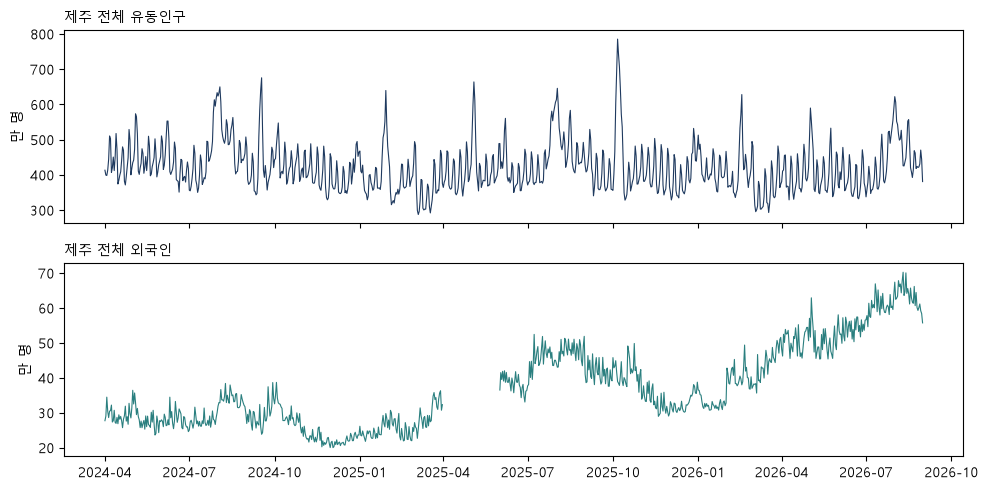

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for a, s, c in zip(ax, ["유동인구", "외국인"], ["#1F3A5F", "#2A7F7F"]):
    x = st.island_series(s); a.plot(x.index, x / 1e4, color=c, lw=.8); a.set_ylabel("만 명"); a.set_title(f"제주 전체 {s}", loc="left", fontsize=10)
plt.tight_layout()

In [4]:
emd, day = "서귀포시 송산동", "2024-09-29"
r = tb.dispatch("nationality_mix", {"date": day, "emd": emd, "top": 3}, "R1").data
print(f"{emd} {day} 외국인 전체 변화(기대값 대비): {r['total_diff']:+,}명")
pd.DataFrame(r["top"])

서귀포시 송산동 2024-09-29 외국인 전체 변화(기대값 대비): +5,654.5명


,nationality,value,expected,diff,share_of_change
0,일본,4170.0,34.0,4136.0,73.1
1,기타,1013.0,302.5,710.5,12.6
2,중국,1127.0,686.5,440.5,7.8


### 외국인 신호 탐지 평가 — 가짜 이상 주입 (`python -m eval.inject_eval --signal 외국인`)

In [5]:
rows = []
for s in ["유동인구", "와이파이", "버스", "외국인"]:
    p = Path(f"eval/results/inject_eval_{s}.json")
    if not p.exists():
        continue
    d = json.loads(p.read_text("utf-8"))
    sw = next(x for x in d["sweep"] if x["method"] == "seasonal_z" and x["threshold"] == 3.5)
    al = next(x for x in d["alarms"] if x["method"] == "seasonal_z" and x["threshold"] == 3.5)
    rows.append({"신호": s, "읍면동": d["regions"], "주입 횟수": d["trials"], "구간 적중률": sw["episode_hit"], "일 재현율": sw["day_recall"], "평소 경보(100일당)": al["alarms_per_100_days"]})
pd.DataFrame(rows)

,신호,읍면동,주입 횟수,구간 적중률,일 재현율,평소 경보(100일당)
0,유동인구,43,480,0.585,0.551,4.07
1,와이파이,43,480,0.279,0.231,3.18
2,버스,41,480,0.381,0.318,3.61
3,외국인,43,480,0.404,0.364,1.85


**읽은 것**
- 외국인 신호도 같은 탐지 방법(점수 3.5)으로 주입한 이상 구간의 40%를 잡는다. 유동인구(59%)보다 낮고 와이파이(28%)·버스(38%)와 비슷하다 — 읍면동별 외국인 수가 작아 날마다 변동이 크기 때문이다
- 평소 경보는 100일당 1.85건으로 네 신호 중 가장 적다
- 유동인구는 기간을 늘리자 평소 경보가 100일당 2.81건(1년치)에서 4.07건으로 늘었다. 2025-10 추석·개천절 7일 연휴, 2025-05 연휴, 2026-02 설처럼 실제 급증이 늘어난 것이다(1년치 결과: `eval/results/_1year/`)

### 외국인 신호에 맞는 공휴일 근거
원인 판정 평가(5절)에서 외국인 신호는 한국 공휴일을 정답으로 둔 구간의 일치율이 55.6%(63건)로 낮았다. 판정이 틀린 것인지, **한국 공휴일이 외국인 방문의 근거가 아닌 것**인지 데이터로 확인한다.
읍면동별 급증(점수 3.5 이상) 비율을 공휴일 앞뒤 1일과 그 외 날로 나눠 비교한다.

In [6]:
import holidays
def surge_ratio(frame, country):
    Z = pd.concat([score_series(frame[c], "seasonal_z")[2].rename(c) for c in frame.columns if frame[c].notna().sum() > 100], axis=1)
    cal = holidays.country_holidays(country, years=range(2024, 2027))
    near = pd.Series([any((d + pd.Timedelta(days=k)).date() in cal for k in (-1, 0, 1)) for d in Z.index], index=Z.index)
    up, ok = Z >= 3.5, Z.notna()
    r1, r0 = up[near].sum().sum() / ok[near].sum().sum() * 100, up[~near].sum().sum() / ok[~near].sum().sum() * 100
    return round(r1, 2), round(r0, 2), round(r1 / r0, 1)
from app.analytics.detect import score_series
f = st._foreign.assign(d=lambda x: pd.to_datetime(x["baseDate"].astype(str)))
def frame(sig=None, nat=None):
    if sig:
        return pd.DataFrame({e: st.series(sig, e) for e in st.regions(sig)})
    return f[f["nationality"] == nat].pivot_table(index="d", columns="emd_full", values="visitPop", aggfunc="sum").reindex(pd.date_range("2024-04-01", "2026-08-31"))
rows = []
for label, fr, countries in [("내국인 유동인구", frame("유동인구"), ["KR"]), ("외국인 전체", frame("외국인"), ["KR", "CN", "JP"]),
                             ("중국 국적", frame(nat="중국"), ["KR", "CN"]), ("일본 국적", frame(nat="일본"), ["KR", "JP"])]:
    for c in countries:
        r1, r0, x = surge_ratio(fr, c)
        rows.append({"대상": label, "공휴일 국가": c, "공휴일 앞뒤 급증 비율(%)": r1, "그 외 날(%)": r0, "배수": x})
pd.DataFrame(rows)

,대상,공휴일 국가,공휴일 앞뒤 급증 비율(%),그 외 날(%),배수
0,내국인 유동인구,KR,17.60,1.88,9.4
1,외국인 전체,KR,1.78,1.62,1.1
2,외국인 전체,CN,2.44,1.55,1.6
3,외국인 전체,JP,2.10,1.57,1.3
4,중국 국적,KR,3.95,2.84,1.4
5,중국 국적,CN,4.71,2.79,1.7
6,일본 국적,KR,6.28,4.86,1.3
7,일본 국적,JP,10.09,4.33,2.3


**읽은 것**: 한국 공휴일 앞뒤에 내국인 급증은 평소의 9배가 넘지만, 외국인 전체는 1.1배로 거의 차이가 없다. 일본인은 일본 공휴일 앞뒤에 2.3배, 중국인은 중국 공휴일 앞뒤에 1.7배다.
→ 외국인 신호를 설명할 때는 **한국 공휴일 대신 중국·일본 공휴일**을 맥락으로 넘기도록 바꿨다(`check_context(..., holiday_countries=("CN", "JP"))`, 테스트 `test_foreign_signal_uses_visitor_country_holidays_not_korean`).
이 변경은 평가 결과를 본 뒤에 한 것이라, 수정 전 결과(`eval/results/judge_eval_before_foreign_holiday.json`)도 함께 둔다.

## 3. 인근 읍면동 동반 변화
읍면동 중심점(정류소·AP 평균 좌표) 사이 거리로 가까운 3곳(15km 이내)을 이웃으로 둔다. 이웃 합계도 같이 움직였다면 '이 동네만의 일'이 아니라 '주변 일대의 흐름'일 가능성이 크다.

In [7]:
pd.DataFrame([{"읍면동": e, "인근(가까운 순)": ", ".join(st.neighbors(e)) or "(15km 안에 없음)"} for e in ["제주시 이호동", "서귀포시 성산읍", "제주시 추자면", "서귀포시 송산동"]])

,읍면동,인근(가까운 순)
0,제주시 이호동,"제주시 도두동, 제주시 외도동, 제주시 노형동"
1,서귀포시 성산읍,"서귀포시 표선면, 제주시 우도면, 제주시 구좌읍"
2,제주시 추자면,(15km 안에 없음)
3,서귀포시 송산동,"서귀포시 정방동, 서귀포시 중앙동, 서귀포시 동홍동"


## 4. 작년 같은 시기 반복
기간을 늘리면서 1년 전 같은 시기(52주 전 같은 요일 ±3일)와 비교할 수 있게 됐다. 그때도 같은 방향 이상(점수 3 이상)이 있었다면 '매년 반복되는 변화일 수 있음'으로 근거에 붙인다.
2025-04 이후 이상 구간 중 몇 개에 반복 근거가 붙는지 센다.

In [8]:
import re
from app.analytics.detect import detect_anomalies, group_episodes
from app.analytics.context import recurrence
rows = []
for s in ["유동인구", "외국인"]:
    for emd in st.regions(s):
        x = st.series(s, emd)
        for e in group_episodes(detect_anomalies(x, threshold=3.5)):
            if e.peak.date < pd.Timestamp("2025-04-01"):
                continue
            rc = recurrence(x, e.peak.date, s)
            rows.append({"신호": s, "읍면동": emd, "가장 큰 날": e.peak.date.date(), "방향": "증가" if e.peak.score > 0 else "감소", "작년 반복": rc is not None, "작년 날짜": re.search(r"\d{4}-\d{2}-\d{2}", rc.detail).group() if rc else ""})
rec = pd.DataFrame(rows)
rec.groupby("신호")["작년 반복"].agg(["sum", "count", "mean"]).round(3)

,sum,count,mean
신호,,,
외국인,47,341,0.138
유동인구,183,367,0.499


공휴일(가장 큰 날 ±1일)과 겹치는 구간은 이미 공휴일 근거가 있다. **공휴일이 아닌데 작년에도 반복된 구간**이 이 근거가 새로 설명하는 부분이다.

In [9]:
import holidays
kr = holidays.KR(years=range(2024, 2027))
rec["공휴일 ±1일"] = rec["가장 큰 날"].map(lambda d: any(d + pd.Timedelta(days=k) in kr for k in (-1, 0, 1)))
display(pd.crosstab([rec["신호"], rec["공휴일 ±1일"]], rec["작년 반복"], margins=True))
new = rec[~rec["공휴일 ±1일"] & rec["작년 반복"]]
new.groupby("가장 큰 날").size().sort_values(ascending=False).head(10).rename("읍면동 수")

작년 반복         False  True  All
신호   공휴일 ±1일                  
외국인  False      253    37  290
     True        41    10   51
유동인구 False       86    87  173
     True        98    96  194
All             478   230  708

가장 큰 날
2025-07-31    12
2026-07-31     8
2026-08-03     7
2025-08-01     6
2026-07-30     6
2025-08-02     5
2025-07-29     5
2026-02-08     4
2026-07-12     4
2026-05-03     4
Name: 읍면동 수, dtype: int64

**읽은 것**
- 2025-04 이후 유동인구 이상 구간의 절반(367개 중 183개)에 '작년에도 그랬음' 근거가 붙는다. 공휴일이 아닌 구간에서도 절반(173개 중 87개)이며, 주로 7월 말~8월 초 휴가철 절정이다 → 그동안 공휴일로 설명되지 않던 구간에 근거가 생겼다
- 외국인 신호는 14%(341개 중 47개)만 반복된다. 외국인 급증은 해마다 같은 시기에 되풀이되는 경우가 적다
- 반복 근거는 '원인'이 아니라 '매년 반복되는 변화일 수 있음'이라는 참고 근거로만 쓴다

## 5. 원인 판정 대규모 평가 (`python -m eval.judge_eval`)
실제 이상 구간 전체에 판정 모델(tev1:4b)을 돌려, 데이터에서 따로 확인되는 사실(공휴일·이름이 명시된 축제·강한 비바람)과 맞는지 본다.
**한계**: 정답이 판정에 넘기는 근거와 같은 자료에서 나온다 → '근거를 제대로 읽는가'를 재는 시험이지, 현장에서 확인한 원인이 아니다.

In [10]:
def summ(p):
    s = json.loads(Path(p).read_text("utf-8"))["summary"]
    out = {"이상 구간": s["episodes"], "정답 있는 구간": s["labeled"], "일치율": s["agree"][0], "근거 제거 시 안 고름": s["ablation_not_chosen"][0], "규칙 일치율": s["rule_agree"][0]}
    out.update({f"{k} 일치(n)": f"{v['agree'][0]} ({v['agree'][1]})" for k, v in s["by_label"].items()})
    return out
pd.DataFrame({"① 1년치·근거 문장 수정 전": summ("eval/results/_1year/judge_eval_before_label.json"),
              "② 1년치·근거 문장 수정 후": summ("eval/results/_1year/judge_eval.json"),
              "③ 기간 연장+외국인·한국 공휴일": summ("eval/results/judge_eval_before_foreign_holiday.json"),
              "④ 기간 연장+외국인·중국·일본 공휴일(현재)": summ("eval/results/judge_eval.json")}).T

,이상 구간,정답 있는 구간,일치율,근거 제거 시 안 고름,규칙 일치율,holiday 일치(n),event 일치(n),weather 일치(n)
① 1년치·근거 문장 수정 전,398,189,0.815,1.0,0.931,0.835 (182),1.0 (2),0.231 (13)
② 1년치·근거 문장 수정 후,398,189,0.952,1.0,0.931,0.978 (182),1.0 (2),0.538 (13)
③ 기간 연장+외국인·한국 공휴일,1262,464,0.909,1.0,0.961,0.925 (453),1.0 (3),0.438 (16)
④ 기간 연장+외국인·중국·일본 공휴일(현재),1262,509,0.882,1.0,0.957,0.896 (498),1.0 (3),0.438 (16)


### 신호별 일치율 (정답이 있는 구간)

In [11]:
def by_signal(p):
    r = pd.DataFrame(json.loads(Path(p).read_text("utf-8"))["rows"])
    r = r[r["labels"].map(len).gt(0)]
    r["agree"] = [c in l for c, l in zip(r["choice"], r["labels"])]
    return r.groupby("signal")["agree"].agg(lambda a: f"{a.mean():.3f} ({len(a)})")
pd.DataFrame({"③ 한국 공휴일": by_signal("eval/results/judge_eval_before_foreign_holiday.json"), "④ 중국·일본 공휴일(현재)": by_signal("eval/results/judge_eval.json")})

,③ 한국 공휴일,④ 중국·일본 공휴일(현재)
signal,,
버스,0.944 (36),0.944 (36)
와이파이,0.909 (22),0.909 (22)
외국인,0.556 (63),0.565 (108)
유동인구,0.971 (343),0.974 (343)


In [12]:
s = json.loads(Path("eval/results/judge_eval.json").read_text("utf-8"))["summary"]
pd.DataFrame({"정답 없음(근거 기간 안)": pd.Series(s["unlabeled_choices"]), "근거 기간 밖(전체)": pd.Series(s["outside_coverage_choices"])}).fillna(0).astype(int)

,정답 없음(근거 기간 안),근거 기간 밖(전체)
holiday,0,237
tourism_demand,151,275
unknown,105,253
weather,0,1


**읽은 것**
- ① → ②: 근거 문장에 맥락 종류(날씨·공휴일 등)를 붙이자 일치율이 81.5% → 95.2%. 날씨는 23% → 54%로 여전히 낮다(13건)
- ③ 기간을 2026-08까지 늘리고 외국인 신호를 넣으니 이상 구간이 1,262개, 정답 있는 구간이 464개로 늘었다. 유동인구·버스·와이파이는 91~97%로 비슷하지만, **외국인은 55.6%**
- 2절에서 본 것처럼 한국 공휴일은 외국인 급증과 거의 관계가 없다(1.1배) → ④ 외국인 신호에는 중국·일본 공휴일을 넘기도록 바꿨다. 외국인 정답 구간이 108개로 늘었지만 일치율은 56.5%로 거의 그대로다. 중국·일본 공휴일도 급증과의 관계가 1.6~2.3배로 약해, '공휴일이 겹치면 정답은 공휴일'이라는 약한 정답 자체가 외국인에게는 잘 맞지 않는다. 이웃 읍면동이 함께 움직였으면 판정은 '관광 수요 변화'를 고르는 경우가 많았다
- **평가를 본 뒤 정답이나 판정 규칙을 더 맞추지 않았다**(맞추면 평가가 의미를 잃는다). ③·④ 결과를 모두 남긴다
- 근거 제거 시험은 모든 경우 100%: 정답 근거를 지우면 그 원인을 고르지 않는다(근거 없이 원인을 지어내지 않음)
- 규칙 판정의 일치율(95.7%)이 더 높은 것은 규칙이 약한 정답을 만드는 방식과 거의 같기 때문이며, 규칙이 더 낫다는 뜻은 아니다